# Control vs. TFAM perturbation

This notebook estimates canonical control and TFAM-perturbed RPE1 cell states from populations of cells. It does not represent longitudinal measurements of individual cells.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../data/raw/replogle22rpe1.h5ad"

adata = sc.read_h5ad(DATA_PATH)
print(adata)

AnnData object with n_obs × n_vars = 240774 × 8749
    obs: 'perturbation'


## Select the experimental populations

In [2]:
experiment = adata[
    adata.obs["perturbation"].isin(["control", "TFAM"])
].copy()

print(experiment)
print(experiment.obs["perturbation"].value_counts())

AnnData object with n_obs × n_vars = 15065 × 8749
    obs: 'perturbation'


perturbation
control    11485
TFAM        3580
Name: count, dtype: int64


In [3]:
tfam = experiment[experiment.obs["perturbation"] == "TFAM"].copy()
control = experiment[experiment.obs["perturbation"] == "control"].copy()

random_state = np.random.RandomState(42)
control_positions = random_state.choice(
    control.n_obs,
    size=tfam.n_obs,
    replace=False,
)
control_sample = control[control_positions].copy()

balanced = sc.concat(
    [control_sample, tfam],
    keys=["control", "TFAM"],
    index_unique="-",
)

print(balanced.obs["perturbation"].value_counts())

perturbation
TFAM       3580
control    3580
Name: count, dtype: int64


## Estimate canonical states and their change

In [4]:
control_mean = np.asarray(control.X.mean(axis=0)).flatten()
tfam_mean = np.asarray(tfam.X.mean(axis=0)).flatten()

state_df = pd.DataFrame({
    "gene": adata.var_names,
    "control": control_mean,
    "TFAM": tfam_mean,
})
state_df["change"] = state_df["TFAM"] - state_df["control"]
state_df["absolute_change"] = state_df["change"].abs()

top_changes = (
    state_df
    .sort_values("absolute_change", ascending=False)
    .head(20)
)

top_changes

,gene,control,TFAM,change,absolute_change
8739,MT-CO2,4.789917,3.143913,-1.646004,1.646004
8741,MT-ATP6,4.349766,2.848875,-1.500891,1.500891
8742,MT-CO3,4.459498,3.143607,-1.315891,1.315891
8736,MT-ND1,3.488636,2.227092,-1.261544,1.261544
8743,MT-ND3,3.221514,1.971010,-1.250504,1.250504
8738,MT-CO1,4.702750,3.516492,-1.186257,1.186257
8737,MT-ND2,3.075387,2.221077,-0.854309,0.854309
8746,MT-ND5,2.877070,2.081756,-0.795314,0.795314
8745,MT-ND4,4.033865,3.270550,-0.763315,0.763315
8747,MT-ND6,1.216720,0.561831,-0.654888,0.654888


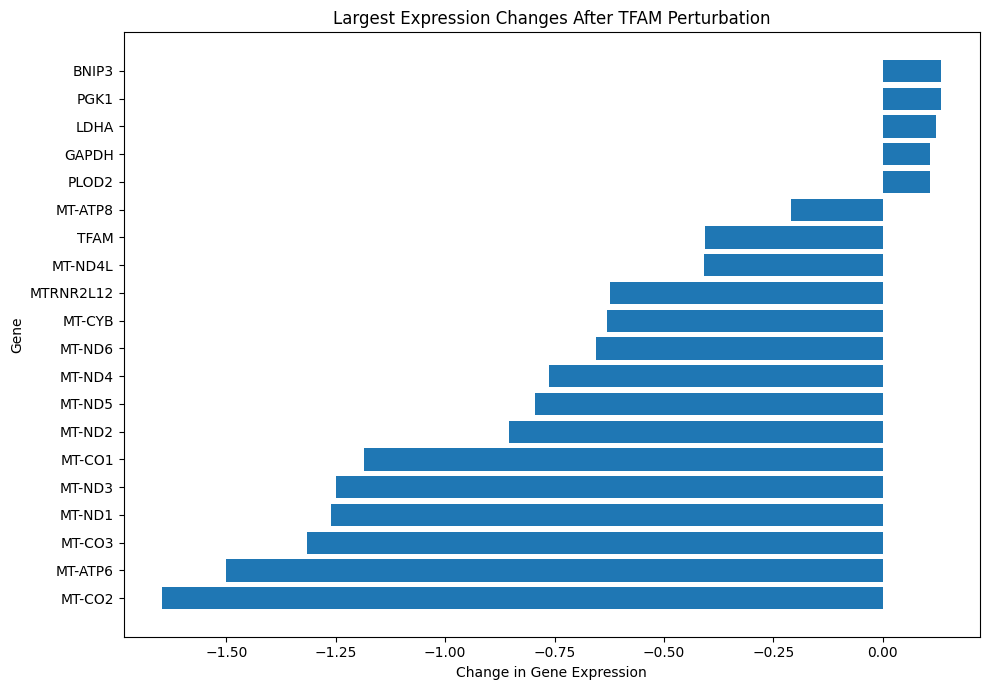

In [5]:
top_plot = top_changes.sort_values("change")

plt.figure(figsize=(10, 7))
plt.barh(top_plot["gene"], top_plot["change"])
plt.xlabel("Change in Gene Expression")
plt.ylabel("Gene")
plt.title("Largest Expression Changes After TFAM Perturbation")
plt.tight_layout()
plt.show()

## Visualize cell-state variation with PCA

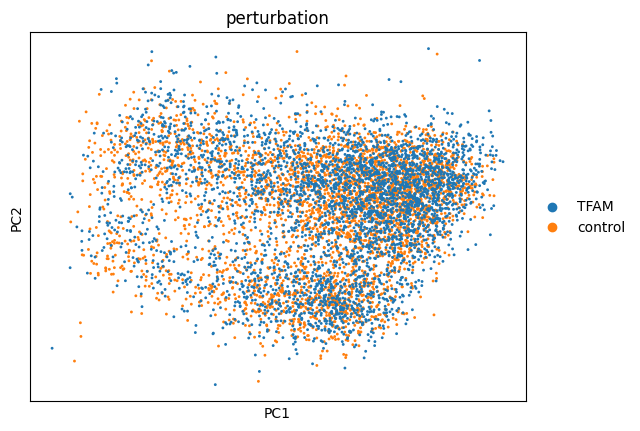

In [6]:
sc.pp.pca(balanced)
sc.pl.pca(balanced, color="perturbation")

## Identify differentially expressed genes

In [7]:
sc.tl.rank_genes_groups(
    balanced,
    groupby="perturbation",
    groups=["TFAM"],
    reference="control",
    method="wilcoxon",
)

sc.get.rank_genes_groups_df(balanced, group="TFAM").head(20)

,names,scores,logfoldchanges,pvals,pvals_adj
0,LDHA,16.105015,0.190094,2.352437e-58,1.286342e-55
1,ENO1,14.246361,0.147161,4.722567e-46,2.430455e-43
2,GAPDH,12.780200,0.165413,2.115244e-37,1.028126e-34
3,RPS2,11.603168,0.066863,3.970972e-31,1.828528e-28
4,RPL41,11.417608,0.077856,3.415033e-30,1.493906e-27
5,ANXA2,11.401405,0.118504,4.114233e-30,1.714068e-27
6,PGK1,11.343072,0.223032,8.027627e-30,3.192441e-27
7,RPS8,10.899524,0.082355,1.158620e-27,4.407289e-25
8,RPS24,10.856947,0.079400,1.848250e-27,6.737642e-25
9,RPL12,10.585810,0.083698,3.467682e-26,1.213550e-23


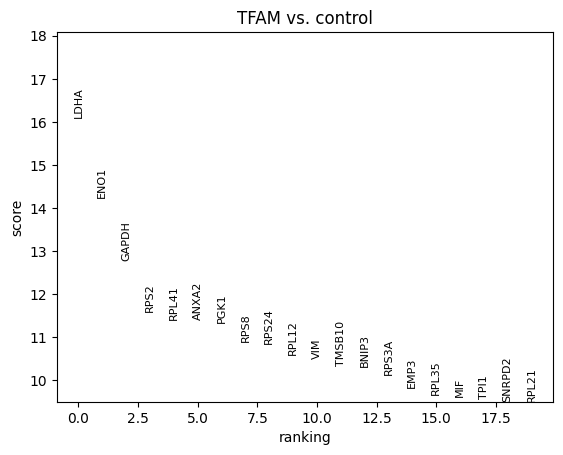

In [8]:
sc.pl.rank_genes_groups(balanced, n_genes=20)